In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

DATA_DIR = "../data"
CSV_PATH = f"{DATA_DIR}/tf2_historico.csv"
HORIZON = 7             # prever o preço daqui a N dias
TARGET_HALF_WINDOW = 2  # alvo = média do preço em t+H-W .. t+H+W (0 = preço de um único dia)
TARGET_CLIP = 0.7       # no treino, corta log-retornos acima de ±0.7 (≈ -50%/+100%: sujeira de dado)
EMA_WEIGHT = 0.5        # previsão final = (1 - w) × modelo + w × "volta para a EMA 10"
TEST_DAYS = 180         # últimos N dias de dados rotulados = conjunto de teste
CV_FOLDS = 4            # validação walk-forward: N semestres antes do teste
FOLD_DAYS = 180
MIN_HISTORY = 30        # descarta os primeiros N dias de cada item (janelas incompletas)
START_DATE = "2016-01-01"  # ignora o começo do mercado (muito ruidoso); None = usa tudo
KEY_ITEM = "Mann Co. Supply Crate Key"
SEED = 42

## 1. Carregar os dados

In [13]:
raw = pd.read_csv(CSV_PATH, low_memory=False)
raw["observation_date"] = pd.to_datetime(raw["observation_date"])
raw["scrape_date"] = pd.to_datetime(raw["scrape_timestamp_utc"].str[:10])

print(f"{len(raw):,} linhas, {raw['market_hash_name'].nunique()} itens, {raw.shape[1]} colunas")
(raw.groupby("market_hash_name")
    .agg(dias=("observation_date", "size"),
         inicio=("observation_date", "min"),
         fim=("observation_date", "max"),
         preco_ultimo=("price", "last"),
         dias_preenchidos=("is_filled", "sum"))
    .sort_values("dias", ascending=False))

90,068 linhas, 37 itens, 61 colunas


,dias,inicio,fim,preco_ultimo,dias_preenchidos
market_hash_name,,,,,
Description Tag,5056,2012-12-12,2026-10-15,0.4515,0
Mann Co. Supply Crate Key,5056,2012-12-12,2026-10-15,10.8075,0
Secret Saxton,4900,2013-05-17,2026-10-15,0.4319,0
Mann Co. Store Package,4900,2013-05-17,2026-10-15,0.4527,0
Battle-Worn Robot Taunt Processor,4711,2013-11-22,2026-10-15,0.2129,0
Reinforced Robot Bomb Stabilizer,4711,2013-11-22,2026-10-15,0.1525,0
Reinforced Robot Humor Suppression Pump,4711,2013-11-22,2026-10-15,0.1434,0
Reinforced Robot Emotion Detector,4711,2013-11-22,2026-10-15,0.1524,0
Nice Winter Crate 2014 Series #89,4322,2014-12-16,2026-10-15,0.1690,27


## 2. Tratamento e alvo

1. **Remove o dia da coleta** — ele só tem as vendas até a hora em que o scraper rodou.
2. Remove duplicatas `(item, data)` e preços `<= 0`.
3. **Alvo = média do preço em `t+H-W .. t+H+W`** (`W = TARGET_HALF_WINDOW`), e não o preço de um único
   dia: nos itens com pouco volume o preço diário é dominado por picos de uma venda isolada, que são
   imprevisíveis e não interessam para decidir compra/venda. Confere que a janela inteira tem dias
   consecutivos (com datas únicas e ordenadas, basta checar que a última linha está a `H+W` dias).
   O modelo prevê o **log-retorno** `log(alvo / preço atual)`, que é comparável entre itens.

In [14]:
df = raw.loc[raw["observation_date"] < raw["scrape_date"],
             ["observation_date", "market_hash_name", "price", "volume", "is_filled",
              "days_since_first_obs"]].copy()
df = (df.drop_duplicates(["market_hash_name", "observation_date"])
        .query("price > 0")
        .sort_values(["market_hash_name", "observation_date"])
        .reset_index(drop=True))

W = TARGET_HALF_WINDOW
by_item = df.groupby("market_hash_name")
window_mean = by_item["price"].transform(lambda s: s.rolling(2 * W + 1).mean())  # média das linhas i-2W..i
df["target_price"] = window_mean.groupby(df["market_hash_name"]).shift(-(HORIZON + W))
window_end = by_item["observation_date"].shift(-(HORIZON + W))
df.loc[(window_end - df["observation_date"]).dt.days != HORIZON + W, "target_price"] = np.nan
df["target_logret"] = np.log(df["target_price"] / df["price"])
print(f"alvo: média do preço em t+{HORIZON - W} .. t+{HORIZON + W}")

alvo: média do preço em t+5 .. t+9


## 3. Features

As features são recalculadas aqui a partir do preço e do volume (em vez de usar as do CSV), todas
**relativas ao preço atual** para generalizar entre itens que custam 0.15 e 10.8:

- **Retornos** passados (1, 3, 7, 14, 30 dias), **distância das médias** (móvel, mediana, EMA),
  volatilidade, mínimo/máximo da janela, z-score, distância da máxima/mínima histórica.
- **Volume** em log e sua tendência (o modelo usa isso para saber se o item é líquido ou não).
- **Mercado**: retorno mediano de todos os itens no dia e o retorno da Key. Ajuda a separar
  "esse item subiu" de "o mercado inteiro subiu".

Ficaram **de fora** de propósito, porque pioraram a validação walk-forward: mês / dia do ano /
dia da semana, idade do item e o nome do item. Com elas o modelo decorava padrões de épocas
passadas (ex.: "em dezembro os cases caem") e errava feio quando o regime mudou (fim de 2025).

In [15]:
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    item = df["market_hash_name"]
    p, lp = df["price"], np.log(df["price"])
    vol = df["volume"].astype(float)
    g, glp, gvol = p.groupby(item), lp.groupby(item), vol.groupby(item)

    def roll(grouped, k, fn):
        return grouped.transform(lambda s: getattr(s.rolling(k, min_periods=1), fn)())

    F = pd.DataFrame(index=df.index)
    F["log_price"] = lp
    for k in (1, 3, 7, 14, 30):
        F[f"ret_{k}"] = lp - glp.shift(k)
    for k in (3, 7, 14, 30, 60):
        F[f"ma_{k}_rel"] = roll(g, k, "mean") / p - 1
    for k in (7, 30):
        F[f"med_{k}_rel"] = roll(g, k, "median") / p - 1
    for span in (5, 10, 30):
        F[f"ema_{span}_rel"] = g.transform(lambda s: s.ewm(span=span, adjust=False).mean()) / p - 1
    daily = glp.diff().groupby(item)
    for k in (7, 30):
        F[f"vol_{k}"] = daily.transform(lambda s: s.rolling(k, min_periods=2).std())
        F[f"min_{k}_rel"] = roll(g, k, "min") / p - 1
        F[f"max_{k}_rel"] = roll(g, k, "max") / p - 1
    F["z_30"] = -F["ma_30_rel"] / (F["vol_30"] + 1e-9)
    F["ath_rel"] = p / g.cummax() - 1
    F["atl_rel"] = p / g.cummin() - 1

    F["log_vol"] = np.log1p(vol)
    for k in (7, 30):
        F[f"log_vol_ma_{k}"] = np.log1p(roll(gvol, k, "mean"))
    F["vol_trend"] = F["log_vol_ma_7"] - F["log_vol_ma_30"]
    F["vol_today_rel"] = F["log_vol"] - F["log_vol_ma_7"]
    F["is_filled"] = df["is_filled"].astype(float)

    date, is_key = df["observation_date"], item.eq(KEY_ITEM)
    market = F.loc[~is_key, ["ret_1", "ret_7"]].groupby(date[~is_key]).median()
    F["mkt_ret_1"] = date.map(market["ret_1"])
    F["mkt_ret_7"] = date.map(market["ret_7"])
    F["key_ret_7"] = date.map(F.loc[is_key, "ret_7"].set_axis(date[is_key]))
    F["rel_to_mkt_7"] = F["ret_7"] - F["mkt_ret_7"]
    return F


features = build_features(df)
FEATURES = list(features.columns)
df = df.drop(columns="is_filled").join(features)  # is_filled volta como feature numérica

latest = df.groupby("market_hash_name").tail(1).copy()  # último dia de cada item → previsão final

df = df[df["days_since_first_obs"] >= MIN_HISTORY]
if START_DATE:
    df = df[df["observation_date"] >= START_DATE]
labeled = df.dropna(subset=["target_logret"]).reset_index(drop=True)

print(f"{len(FEATURES)} features")
print(f"linhas rotuladas: {len(labeled):,}  |  itens: {labeled['market_hash_name'].nunique()}")
print(f"período: {labeled['observation_date'].min().date()} .. {labeled['observation_date'].max().date()}")
labeled["target_logret"].describe(percentiles=[.01, .05, .5, .95, .99])

35 features
linhas rotuladas: 80,365  |  itens: 36
período: 2016-01-01 .. 2026-10-05


count   80365.0000
mean        0.0182
std         0.2585
min        -3.8875
1%         -0.6858
5%         -0.3754
50%         0.0060
95%         0.4481
99%         0.7663
max         3.7523
Name: target_logret, dtype: float64

## 4. Split temporal (treino / teste)

Holdout por **data**, nunca aleatório: embaralhar colocaria o futuro no treino. Entre o fim do treino
e o início do teste fica um intervalo de `H + W` dias, porque o alvo olha até `t+H+W`.

In [16]:
test_start = labeled["observation_date"].max() - pd.Timedelta(days=TEST_DAYS - 1)
train_end = test_start - pd.Timedelta(days=HORIZON + W)

train = labeled[labeled["observation_date"] < train_end].sort_values("observation_date")
test = labeled[labeled["observation_date"] >= test_start].sort_values("observation_date")

X_train, y_train = train[FEATURES], train["target_logret"]
X_test, y_test = test[FEATURES], test["target_logret"]

print(f"treino: {train['observation_date'].min().date()} .. {train['observation_date'].max().date()}  ({len(train):,} linhas)")
print(f"teste:  {test['observation_date'].min().date()} .. {test['observation_date'].max().date()}  ({len(test):,} linhas)")

treino: 2016-01-01 .. 2026-03-30  (73,817 linhas)
teste:  2026-04-09 .. 2026-10-05  (6,242 linhas)


## 5. Modelos

- **Ingênuo** — "o preço não muda" (retorno 0).
- **EMA 10** — "o preço volta para a média móvel exponencial de 10 dias". Captura sozinha a maior
  parte da reversão à média dos itens com pouco volume, então é a baseline que importa.
- **HGB** — `HistGradientBoostingRegressor` com `loss="absolute_error"` (a métrica é MAE e o retorno
  tem caudas pesadas) e árvores pequenas (`max_leaf_nodes=7`, `min_samples_leaf=200`): árvores
  maiores decoravam o passado e iam pior na validação. Treina com o alvo cortado em `±TARGET_CLIP`.
- **HGB + EMA (final)** — média de `HGB` e `EMA 10` (peso `EMA_WEIGHT`). Foi a variante mais estável
  na validação walk-forward: o HGB ganha da EMA quando o mercado se comporta como no passado, a EMA
  segura o erro quando o regime muda.

In [17]:
class RatioBaseline(BaseEstimator, RegressorMixin):
    """Baseline sem treino: 'o preço vai para a média' → prevê log(1 + col), col = média/preço − 1."""

    def __init__(self, col="ema_10_rel"):
        self.col = col

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.nan_to_num(np.log1p(X[self.col].to_numpy(dtype=float)))


class EMABlend(BaseEstimator, RegressorMixin):
    """Treina `estimator` com o alvo cortado e mistura a previsão com a baseline da EMA 10."""

    def __init__(self, estimator, ema_weight=EMA_WEIGHT, clip=TARGET_CLIP):
        self.estimator = estimator
        self.ema_weight = ema_weight
        self.clip = clip

    def fit(self, X, y):
        self.model_ = clone(self.estimator).fit(X, np.clip(y, -self.clip, self.clip))
        return self

    def predict(self, X):
        ema = RatioBaseline("ema_10_rel").predict(X)
        return (1 - self.ema_weight) * self.model_.predict(X) + self.ema_weight * ema


hgb = HistGradientBoostingRegressor(
    loss="absolute_error", learning_rate=0.03, max_leaf_nodes=7, min_samples_leaf=200,
    max_iter=600, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
    random_state=SEED)

NAIVE, EMA, FINAL = "Ingênuo", "EMA 10", "HGB + EMA (final)"
candidates = {
    NAIVE: DummyRegressor(strategy="constant", constant=0.0),
    EMA: RatioBaseline("ema_10_rel"),
    "HGB": EMABlend(hgb, ema_weight=0.0),
    FINAL: EMABlend(hgb, ema_weight=EMA_WEIGHT),
}

## 6. Validação walk-forward

Uma única janela de validação é sorte demais: no fim de 2025 o mercado subiu forte e ficou lá, e
qualquer modelo de reversão à média sofre. Por isso a escolha do modelo usa **4 semestres seguidos
antes do teste**; em cada um, os modelos treinam só com o que veio antes (respeitando o intervalo
de `H + W` dias).

Métrica: **ganho de MAE do log-retorno sobre o ingênuo** (%), e % dos itens em que o modelo ganha do
ingênuo. Em log-retorno, um item de 10.8 (Key) não pesa 70× mais que um case de 0.15.

In [18]:
def walk_forward_folds(dates: pd.Series):
    gap = pd.Timedelta(days=HORIZON + W)
    anchor = dates.max() + pd.Timedelta(days=1)
    for k in range(CV_FOLDS, 0, -1):
        ev_end = anchor - pd.Timedelta(days=FOLD_DAYS * (k - 1))
        ev_start = ev_end - pd.Timedelta(days=FOLD_DAYS)
        label = f"{ev_start.date()} .. {(ev_end - pd.Timedelta(days=1)).date()}"
        yield label, dates < ev_start - gap, (dates >= ev_start) & (dates < ev_end)


cv_rows = []
for label, fit_mask, eval_mask in walk_forward_folds(train["observation_date"]):
    y_eval = y_train[eval_mask].to_numpy()
    items = train.loc[eval_mask, "market_hash_name"].to_numpy()
    row = {"período": label}
    for name, model in candidates.items():
        pred = clone(model).fit(X_train[fit_mask], y_train[fit_mask]).predict(X_train[eval_mask])
        err, err_naive = np.abs(y_eval - pred), np.abs(y_eval)
        row[f"{name} | ganho_%"] = 100 * (1 - err.mean() / err_naive.mean())
        if name != NAIVE:
            row[f"{name} | itens_ok_%"] = 100 * np.mean(
                [err[items == it].mean() < err_naive[items == it].mean() for it in np.unique(items)])
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index("período").drop(columns=f"{NAIVE} | ganho_%")
cv_table.loc["média"] = cv_table.mean()
cv_table.T

período,2024-04-10 .. 2024-10-06,2024-10-07 .. 2025-04-04,2025-04-05 .. 2025-10-01,2025-10-02 .. 2026-03-30,média
EMA 10 | ganho_%,30.3464,30.4035,34.7339,11.1041,26.6470
EMA 10 | itens_ok_%,92.8571,93.5484,93.7500,85.2941,91.3624
HGB | ganho_%,32.0039,33.8369,33.6701,5.7550,26.3165
HGB | itens_ok_%,96.4286,96.7742,93.7500,73.5294,90.1205
HGB + EMA (final) | ganho_%,32.0288,32.7163,35.3153,11.1615,27.8055
HGB + EMA (final) | itens_ok_%,92.8571,96.7742,93.7500,88.2353,92.9042


## 7. Métricas no teste

Treina tudo no período de treino completo e avalia nos últimos `TEST_DAYS` dias. O modelo final já
foi escolhido na validação; o teste só confirma.

- **MAE / RMSE** — erro do preço previsto, na moeda do histórico.
- **MAPE** — erro percentual médio do preço.
- **R² (retorno)** — quanto da variação do retorno o modelo explica (0 = igual a prever a média).
- **Acerto de direção** — % de vezes que o sinal do retorno previsto bate com o real, contando só os
  dias em que o preço mudou. O ingênuo prevê sempre 0, então não tem direção.
- **Ganho vs ingênuo / vs EMA** — redução do MAE em relação a cada baseline (positivo = melhor).

In [19]:
def price_metrics(y_true, y_pred, price_now) -> dict:
    true_p = price_now * np.exp(y_true)
    pred_p = price_now * np.exp(y_pred)
    moved = y_true != 0
    direction = (np.nan if np.allclose(y_pred, 0)
                 else 100 * np.mean(np.sign(y_pred[moved]) == np.sign(y_true[moved])))
    return {
        "MAE": mean_absolute_error(true_p, pred_p),
        "RMSE": np.sqrt(mean_squared_error(true_p, pred_p)),
        "MAPE_%": 100 * mean_absolute_percentage_error(true_p, pred_p),
        "R2_retorno": r2_score(y_true, y_pred),
        "acerto_direcao_%": direction,
    }


models = {name: clone(m).fit(X_train, y_train) for name, m in candidates.items()}
preds = {name: np.asarray(m.predict(X_test)) for name, m in models.items()}
results = pd.DataFrame({name: price_metrics(y_test.to_numpy(), p, test["price"].to_numpy())
                        for name, p in preds.items()}).T
results["ganho_vs_ingenuo_%"] = 100 * (1 - results["MAE"] / results.loc[NAIVE, "MAE"])
results["ganho_vs_ema_%"] = 100 * (1 - results["MAE"] / results.loc[EMA, "MAE"])
results

,MAE,RMSE,MAPE_%,R2_retorno,acerto_direcao_%,ganho_vs_ingenuo_%,ganho_vs_ema_%
Ingênuo,0.0939,0.8836,11.0685,-0.0037,NaN,0.0000,-13.4553
EMA 10,0.0828,0.6477,9.3147,0.3275,72.0328,11.8596,0.0000
HGB,0.0756,0.6384,7.8733,0.2489,72.4188,19.5076,8.6771
HGB + EMA (final),0.0742,0.6176,8.1060,0.3645,72.8369,21.0640,10.4429


In [20]:
best = models[FINAL]

eval_df = test[["market_hash_name", "observation_date", "price", "volume", "target_price"]].copy()
eval_df["pred_price"] = eval_df["price"] * np.exp(preds[FINAL])
eval_df["naive_price"] = eval_df["price"]
eval_df["ema_price"] = eval_df["price"] * np.exp(preds[EMA])

per_item = (eval_df.groupby("market_hash_name")
            .apply(lambda g: pd.Series({
                "volume_mediano": g["volume"].median(),
                "MAE_modelo": mean_absolute_error(g["target_price"], g["pred_price"]),
                "MAE_ingenuo": mean_absolute_error(g["target_price"], g["naive_price"]),
                "MAE_ema": mean_absolute_error(g["target_price"], g["ema_price"]),
                "MAPE_modelo_%": 100 * mean_absolute_percentage_error(g["target_price"], g["pred_price"]),
            }), include_groups=False))
per_item["ganho_vs_ingenuo_%"] = 100 * (1 - per_item["MAE_modelo"] / per_item["MAE_ingenuo"])
per_item["ganho_vs_ema_%"] = 100 * (1 - per_item["MAE_modelo"] / per_item["MAE_ema"])
print(f"itens em que o modelo ganha do ingênuo: {(per_item['ganho_vs_ingenuo_%'] > 0).sum()} de {len(per_item)}")
per_item.sort_values("ganho_vs_ingenuo_%", ascending=False)

itens em que o modelo ganha do ingênuo: 32 de 36


,volume_mediano,MAE_modelo,MAE_ingenuo,MAE_ema,MAPE_modelo_%,ganho_vs_ingenuo_%,ganho_vs_ema_%
market_hash_name,,,,,,,
Reinforced Robot Emotion Detector,102.5000,0.0029,0.0064,0.0030,1.8315,54.4068,3.0572
Winter 2021 Cosmetic Case,21.0000,0.0074,0.0152,0.0077,4.5937,51.6140,4.5863
Winter 2023 Cosmetic Case,119.0000,0.0045,0.0086,0.0047,2.7828,48.4629,6.1084
Winter 2024 Cosmetic Case,142.0000,0.0039,0.0075,0.0040,2.4756,47.8900,2.8204
Summer 2023 Cosmetic Case,230.0000,0.0033,0.0062,0.0034,2.0638,47.1982,4.0689
Summer 2026 War Paint Case,701.0000,0.0028,0.0053,0.0028,1.8382,47.0667,-1.2955
Reinforced Robot Humor Suppression Pump,99.5000,0.0034,0.0063,0.0036,2.1249,47.0322,5.9462
Winter 2020 Cosmetic Case,31.5000,0.0068,0.0128,0.0069,4.4378,46.5677,1.0649
Summer 2021 Cosmetic Case,107.5000,0.0038,0.0070,0.0039,2.3464,46.4903,4.2098


### Real × previsto

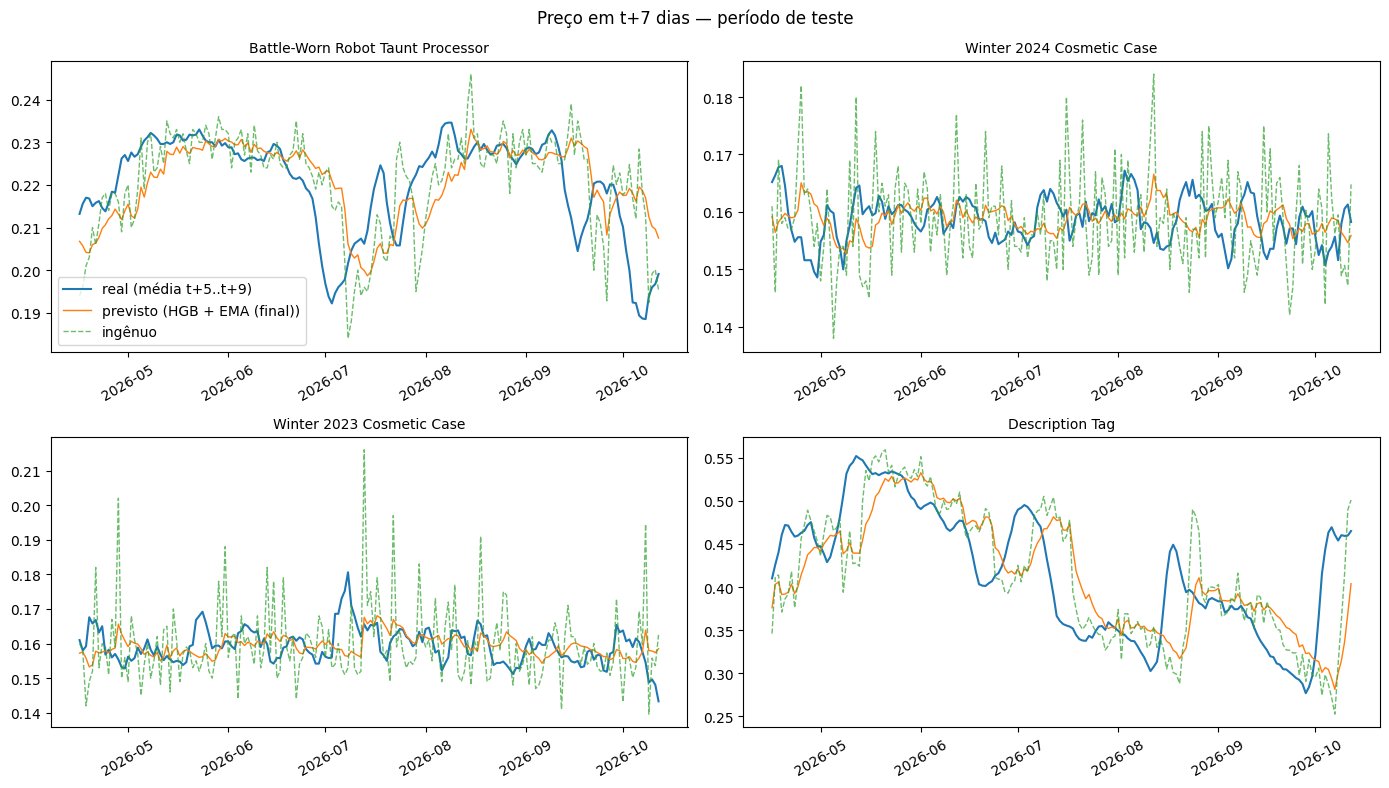

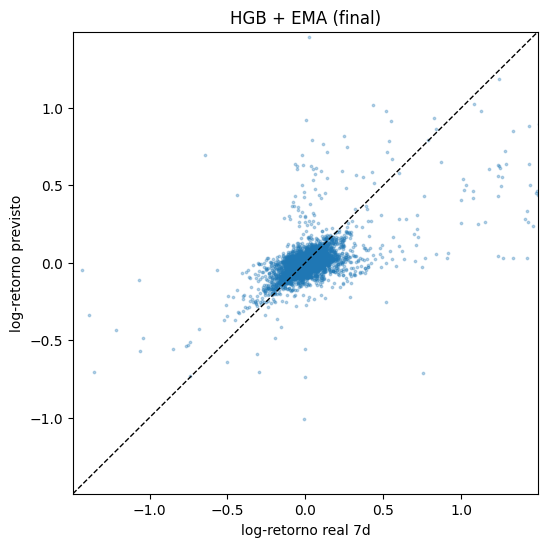

In [21]:
top_items = test["market_hash_name"].value_counts().index[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, item in zip(axes.flat, top_items):
    g = eval_df[eval_df["market_hash_name"] == item]
    target_day = g["observation_date"] + pd.Timedelta(days=HORIZON)
    ax.plot(target_day, g["target_price"], label=f"real (média t+{HORIZON - W}..t+{HORIZON + W})", lw=1.5)
    ax.plot(target_day, g["pred_price"], label=f"previsto ({FINAL})", lw=1)
    ax.plot(target_day, g["naive_price"], label="ingênuo", lw=1, ls="--", alpha=.7)
    ax.set_title(item, fontsize=10)
    ax.tick_params(axis="x", rotation=30)
axes.flat[0].legend()
fig.suptitle(f"Preço em t+{HORIZON} dias — período de teste")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, preds[FINAL], s=3, alpha=.3)
lim = np.quantile(np.abs(y_test), .99)
ax.plot([-lim, lim], [-lim, lim], "k--", lw=1)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim),
       xlabel=f"log-retorno real {HORIZON}d", ylabel="log-retorno previsto", title=FINAL)
plt.show()

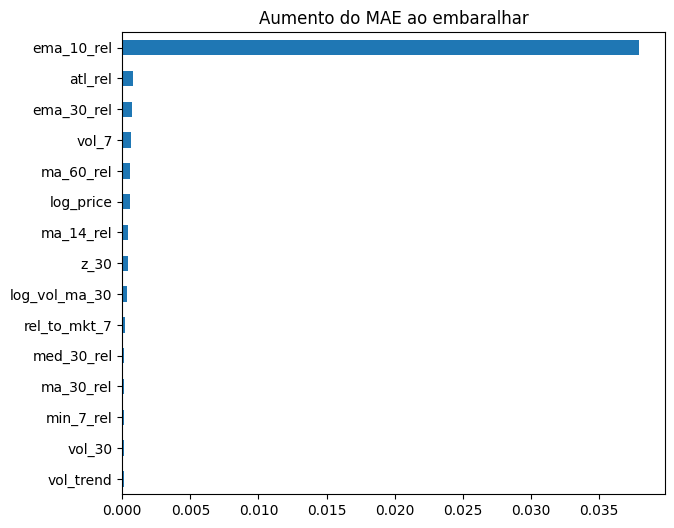

In [22]:
sample = test.sample(min(5000, len(test)), random_state=SEED)
imp = permutation_importance(best, sample[FEATURES], sample["target_logret"],
                             scoring="neg_mean_absolute_error", n_repeats=5,
                             random_state=SEED, n_jobs=-1)
importances = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importances.tail(15).plot.barh(figsize=(7, 6), title="Aumento do MAE ao embaralhar")
plt.show()

## 8. Previsão para os próximos dias

Treina o modelo final com todos os dados rotulados e prevê a partir do último dia de cada item.
`preco_previsto` é a previsão do **preço médio entre `t+H-W` e `t+H+W`**. Retornos grandes em itens
com pouquíssimo volume quase sempre significam "o preço de hoje é um pico e deve voltar", e não
uma tendência.

In [23]:
final_model = clone(candidates[FINAL]).fit(labeled[FEATURES], labeled["target_logret"])

forecast = latest[["market_hash_name", "observation_date", "price", "volume", "days_since_first_obs"]].copy()
forecast["retorno_previsto_%"] = 100 * (np.exp(final_model.predict(latest[FEATURES])) - 1)
forecast["preco_previsto"] = forecast["price"] * (1 + forecast["retorno_previsto_%"] / 100)
forecast["data_alvo"] = forecast["observation_date"] + pd.Timedelta(days=HORIZON)
forecast["historico_curto"] = forecast["days_since_first_obs"] < MIN_HISTORY
forecast = (forecast.rename(columns={"observation_date": "data_base", "price": "preco_atual"})
                    .drop(columns="days_since_first_obs")
                    .sort_values("retorno_previsto_%", ascending=False)
                    .reset_index(drop=True))

output_path = f"{DATA_DIR}/previsao_{HORIZON}d.csv"
forecast.to_csv(output_path, index=False)
print(f"salvo em {output_path}")
forecast

salvo em previsao_7d.csv


,market_hash_name,data_base,preco_atual,volume,retorno_previsto_%,preco_previsto,data_alvo,historico_curto
0,Haunted Hoard Case,2026-10-14,0.1527,23681,59.6795,0.2438,2026-10-21,True
1,Nice Winter Crate 2014 Series #89,2026-10-14,0.1179,12,31.2184,0.1547,2026-10-21,False
2,Secret Saxton,2026-10-14,0.6145,426,29.0179,0.7928,2026-10-21,False
3,Winter 2023 Cosmetic Case,2026-10-14,0.1156,140,24.0949,0.1435,2026-10-21,False
4,Summer 2021 Cosmetic Case,2026-10-14,0.1360,37,14.1706,0.1553,2026-10-21,False
5,Summer 2025 Cosmetic Case,2026-10-14,0.1330,53,13.9877,0.1516,2026-10-21,False
6,Winter 2024 Cosmetic Case,2026-10-14,0.1407,73,11.8185,0.1573,2026-10-21,False
7,Summer 2023 War Paint Case,2026-10-14,0.2038,249,7.4663,0.2190,2026-10-21,False
8,Mann Co. Store Package,2026-10-14,0.4612,3917,7.2163,0.4945,2026-10-21,False
9,Summer 2024 Cosmetic Case,2026-10-14,0.1744,218,7.1443,0.1869,2026-10-21,False
